此文件用于在LangGraph例程基础上构建简单版本的AgentRAG，这里的P改名为Strategist
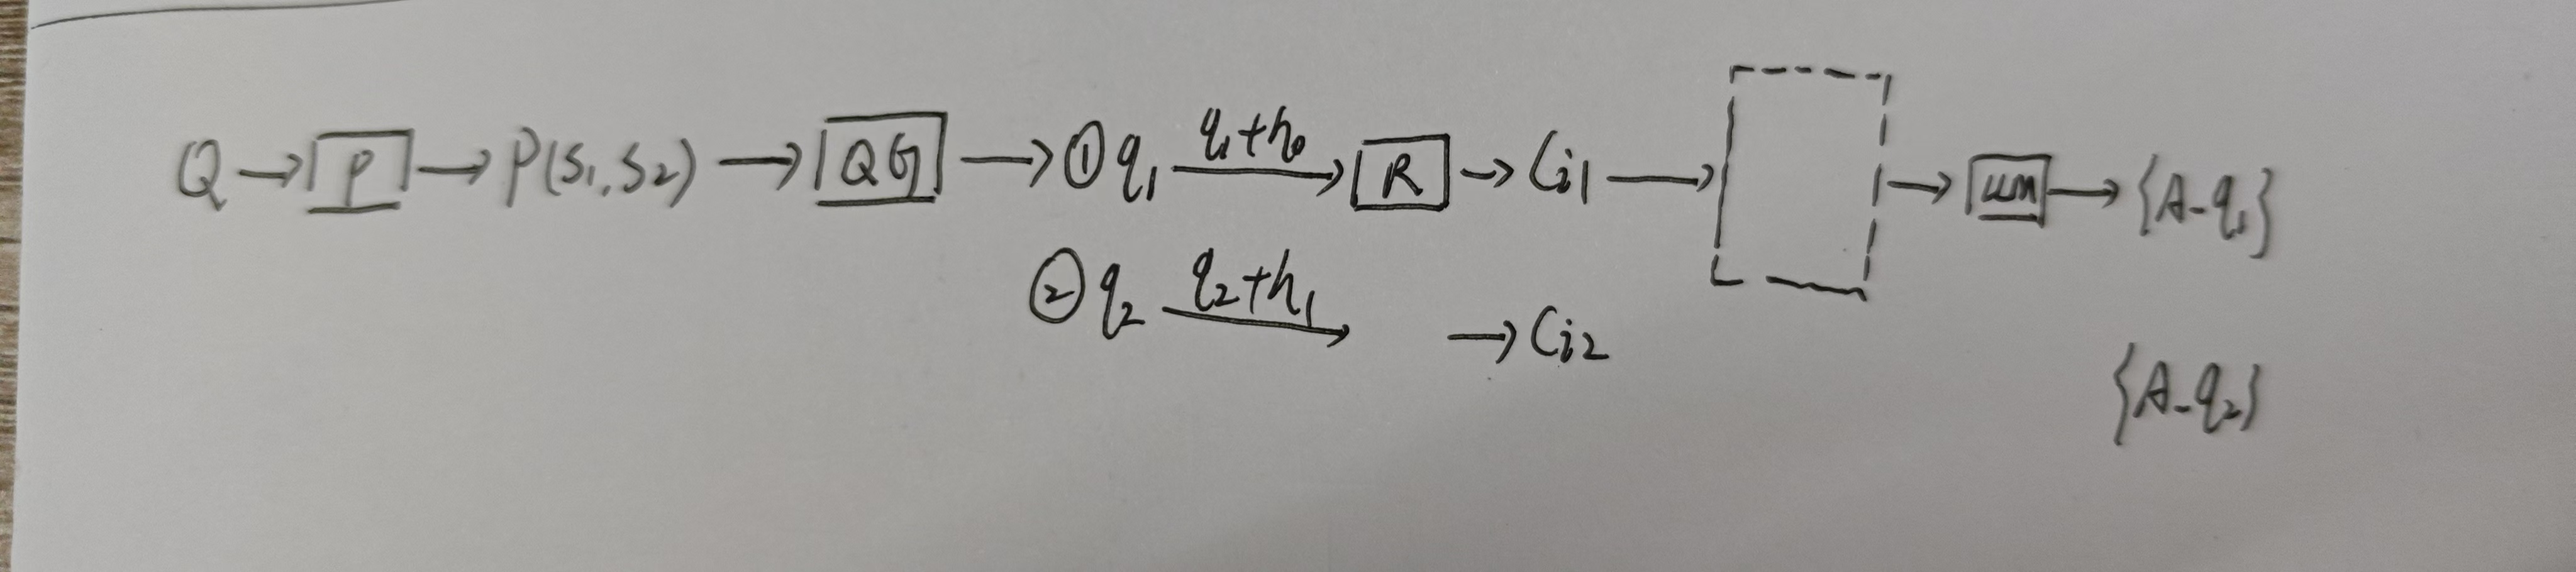

In [9]:
# 构建Query Generator节点，根据计划生成具体查询query
QUERY_GENERATOR_PROMPT = (
    "You will be given a plan, the current step, and the results from finished"
    "steps, decide the task for this step.Output the type of task and the query."
    "The query need to be in detail, include all of information from, previous step's results in the query if it maked, especially for aggregate task. Be concise."
    "User:"
    "Plan: {plan}"
    "Current step: {cur_step}"
    "Results of finished steps:"
    "{memory}"
)


——————————————————————以上是草稿——————————————————————  


——————————————————————检索数据库与工具—————————————————————

In [10]:
# 这里直接读取本地的doc_splits.pkl文件，而不是重新加载
import pickle

# with open("/home/lab/ybw/LangGraph_Agentic RAG/doc_splits.pkl", "wb") as f:
#     pickle.dump(doc_splits, f)  #保存doc_splits.pkl文件到本地

with open("/home/lab/ybw/LangGraph_Agentic RAG/doc_splits.pkl", "rb") as f:
    doc_splits = pickle.load(f)

doc_splits[0].page_content.strip() #取出第一文档块，提取文本内容，并去掉字符串开头结尾的空白字符

"Reward Hacking in Reinforcement Learning | Lil'Log\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\nLil'Log\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n|\n\n\n\n\n\n\nPosts\n\n\n\n\nArchive\n\n\n\n\nSearch\n\n\n\n\nTags\n\n\n\n\nFAQ"

In [11]:
from langchain.text_splitter import RecursiveCharacterTextSplitter
from langchain_community.document_loaders import WebBaseLoader
from langchain_community.vectorstores import InMemoryVectorStore # 
from langchain_community.embeddings import HuggingFaceEmbeddings
from langchain.tools.retriever import create_retriever_tool

local_model_path = "/home/lab/Shared_model/all-MiniLM-L6-v2"
embedding_model = HuggingFaceEmbeddings(
    model_name = local_model_path,
    model_kwargs = {'device': 'cuda:1'}
)
print("嵌入模型加载成功！")

vectorstore = InMemoryVectorStore.from_documents(
    documents=doc_splits,
    embedding=embedding_model
)

retriever = vectorstore.as_retriever()
print("向量存储创建成功！")

retriever_tool = create_retriever_tool(
    retriever,
    "retrieve_blog_posts",
    "Search and return information about Lilian Weng blog posts.",
)

print("检索工具创建成功！")


嵌入模型加载成功！
向量存储创建成功！
检索工具创建成功！


——————————————————————记事本——————————————————————  
——————————————————————记单步和全局数据—————————————————————

In [12]:
# 构建记事本
from typing import List, TypedDict, Annotated
from langchain_core.messages import BaseMessage
import operator

# 这是表示一步的结果
class StepOutput(TypedDict):
    sub_question: str
    retrieved_docs: List[str] # 检索文档为字符串列表
    answer: str

#这是全局的所有历史
class GraphState(TypedDict):
    """
    Represents the state of our graph,indicating the whole history.
    Attributes:
        original_question: The original user question.
        plan: A list of steps to take to answer the question.
        history: A list of StepOutput, accumulating the results of each Node and conditional edge.
        messages: A list of messages, used for ToolCalling and oother interactions with the LLM.
    """
    # 用户原始问题
    original_question: str
    
    #顶层计划，规划阶段的输出
    plan: List[str]

    #循环执行子query阶段的累计状态
    #Annorated[list[StepOutput], operator.add]告诉LangGraph：
    #当一个节点返回‘history’字段时，不要覆盖旧值，而是将新值追加到列表末尾
    history: Annotated[list, operator.add] #这个的list表示的是history类型，operator.add表示新加入的内容
    
    # 这是每个节点临时的对话流
    messages: Annotated[list, operator.add]



——————————————————————Strategist——————————————————————

In [13]:
# from langgraph.graph import MessagesState
from langchain_ollama import ChatOllama
from pydantic import BaseModel, Field
from typing import List


# 使用的模型
response_model = ChatOllama(
    model="qwen3:8b", 
    temperature=0
)

# 
class Plan(BaseModel):
    """A structured plan to answer user's question"""
    steps: List[str] = Field(  # steps属性的描述，要求
        description="A list of clear, logically sequenced, and non-overlapping question or steps that lead to the final answer"
    )

In [14]:
# 构建Strategist节点，接受用户输出生成顶层计划
STRATEGIST_PROMPT = (
    "You are a master strategist. Your task is to create a structured, step-by-step plan to answer a complex user question. "
    "Analyze the user's question to identify its core components and any multi-step reasoning required. "
    "Deconstruct the question into a series of simpler, sequential, and non-overlapping sub-questions that, when answered, will lead to the final comprehensive answer. "
    "Ensure each step is a clear, answerable question. Your final output MUST be a list of these steps.\n\n"
    "User Question: {question}"
)

# 这里Planner替换成Strategist
def Strategist_node(state: GraphState):
    """Takes the user's original question from the state and generates a multo-step plan."""
    print("--- 🧠 Entering Strategist Node ---")
    question = state["original_question"]

    prompt = STRATEGIST_PROMPT.format(question=question)

    structured_llm = response_model.with_structured_output(Plan) # 要求structured_llm返回Plan类型的输出
    print("structured_llm--: ", structured_llm,"\n")
    plan_object = structured_llm.invoke([{"role": "user", "content": prompt}])
    print("plan_object--: ", plan_object,"\n")
    plan_steps = plan_object.steps
    print(f"Generated Plan: {plan_steps}")

    return {"plan": plan_steps}



In [15]:
state = {
    "original_question": "如何用Python写一个爬虫来抓取网页数据？",
    "plan": [],
    "history": [],
    "messages": []
}

# 调用 Strategist_node
result = Strategist_node(state)

print("返回结果：", result)


--- 🧠 Entering Strategist Node ---
structured_llm--:  first=RunnableBinding(bound=ChatOllama(model='qwen3:8b', temperature=0.0), kwargs={'format': {'description': "A structured plan to answer user's question", 'properties': {'steps': {'description': 'A list of clear, logically sequenced, and non-overlapping question or steps that lead to the final answer', 'items': {'type': 'string'}, 'title': 'Steps', 'type': 'array'}}, 'required': ['steps'], 'title': 'Plan', 'type': 'object'}, 'ls_structured_output_format': {'kwargs': {'method': 'json_schema'}, 'schema': <class '__main__.Plan'>}}, config={}, config_factories=[]) middle=[] last=PydanticOutputParser(pydantic_object=<class '__main__.Plan'>) 

plan_object--:  steps=['如何确定需要爬取的网页的目标网站和具体数据？', '如何使用Python的requests库发送HTTP请求获取网页内容？', '如何解析获取的网页内容以提取所需数据？', '如何处理网页中的动态内容（如JavaScript渲染的页面）？', '如何存储爬取到的数据（如保存到文件或数据库）？', '如何设置和管理爬虫的请求频率以避免被网站封禁？', '如何处理网页中的反爬虫机制（如验证码、IP封锁）？', '如何确保爬虫的合法性和遵守网站的robots.txt规则？'] 

Generated Plan: ['如何确定需要爬取的网页的目标网站和

——————————————————————sub_answer_generator——————————————————————

In [19]:
SUB_ANSWER_PEOMPT = (
    "YOu are an expert question-answering assistant. Your task is too provide a concise answer to a sub-question."
    "based ONL Y on the privifrf context.Do not use any prior knowledge."
    "If the context does not contain the answer, simply state that the answer is not found in the context.\n\n"
    "Here is the context retrieved from the knowledge base:\n"
    "---------------------\n"
    "{context}\n"
    "---------------------\n"
    "Here is the sub-question you need to answer:\n"
    "{sub_question}"
)

def sub_answer_generator_node(state: GraphState):
    """Generates an answer for a single sub-question based on the retrieved documents.
    After generating the answer, it updates the 'history' in the state."""
    print("--- 🤖 Entering Sub-Answer Generation Node ---")

    # 1. 获取检索到的文档
    # 2. 获取来自检索工具检索到的文档content
    retrieved_docs_messages = [msg for msg in state["messages"] if msg.type == "tool"]
    context = "\n\n".join([doc.content for doc in retrieved_docs_messages])

    # print("retrieved_docs_messages--:", retrieved_docs_messages)
    # print("context--:", context)

    # 2. 获取当前的子问题
    #    当前的子问题，是由Query Generator生成的、最新的用户消息
    # sub_question = state["messages"][-2].content
    sub_question = ""
    for msg in reversed(state["messages"]): # 从后往前遍历
        if msg.type == "human": # 找到第一个（也就是最新的）'human'消息
            sub_question = msg.content # 这才是我们真正的子问题！
            break

    prompt = SUB_ANSWER_PEOMPT.format(context=context, sub_question=sub_question)

    response = response_model.invoke([{"role": "user", "content": prompt}])
    sub_answer = response.content
    print(f"Generated Sub-Answer:{sub_answer[:200]}...")

    # 更新状态
    step_output = {
        "sub_question": sub_question,
        "retrieved_docs": [doc.content for doc in retrieved_docs_messages], #
        "answer": sub_answer
    }

    return {"history": [step_output]}


from langchain_core.messages import AIMessage, ToolMessage, HumanMessage

# 1. 手动伪造一个刚刚经过了Query Generator和Retrieve节点的state
fake_state_for_sub_answer = {
    "original_question": "Lilian Weng的父亲的父亲是谁？",
    "plan": ["找出Lilian Weng的父亲是谁", "找出她父亲的父亲是谁"],
    "history": [], # 假设这是第一步，所以history是空的
    "messages": [
        HumanMessage(content="Lilian Weng的父亲是谁?"), # 这是QG生成的子问题
        AIMessage(content="", tool_calls=[{"name": "retrieve_blog_posts", "args": {"query": "Lilian Weng's father"}, "id": "1"}]), # 这是QG的输出
        ToolMessage(content="Lilian Weng's father is a computer scientist named Dr. Alex Weng.", tool_call_id="1") # 这是Retrieve的输出
    ]
}

update_result = sub_answer_generator_node(fake_state_for_sub_answer)

import pprint  
pprint.pprint(update_result)

--- 🤖 Entering Sub-Answer Generation Node ---
Generated Sub-Answer:<think>
Okay, the user is asking "Lilian Weng的父亲是谁?" which means "Who is Lilian Weng's father?" in Chinese. Let me check the provided context.

The context says: "Lilian Weng's father is a computer sc...
{'history': [{'answer': '<think>\n'
                        'Okay, the user is asking "Lilian Weng的父亲是谁?" which '
                        'means "Who is Lilian Weng\'s father?" in Chinese. Let '
                        'me check the provided context.\n'
                        '\n'
                        'The context says: "Lilian Weng\'s father is a '
                        'computer scientist named Dr. Alex Weng." So the '
                        'answer should be Dr. Alex Weng. I need to make sure '
                        'not to use any prior knowledge and only rely on the '
                        'given context. Since the context directly answers the '
                        "question, I'll provide that inform

——————————————————————final_synthesis_generator——————————————————————

In [ ]:
FINAL_SYNTHESIS_PROMPT = (
    "You are an expert synthesizer.Your task is to compose a comprehensive."
    "cohesive, and well-structured final answer to the user's original question."
    
)